In [1]:
pip install iTransformer optuna pandas numpy scikit-learn torch matplotlib

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [2]:
# Import shared modules
import sys
sys.path.append('.')

from data_loader import load_btc_data, load_technical_data, merge_dataframes, create_hourly_data, create_validation_periods, create_sequences
from model_utils import load_model, make_predictions, prepare_tensor
from backtest_functions import backtest_profit_threshold_with_trades, backtest_profit_threshold, backtest_ts_momentum
from utils import cv_optimize_threshold_parameters, cv_optimize_risk_parameters, cv_optimize_momentum_parameters, plot_trades, save_trades_to_csv, create_trades_dataframe

# Force reload modules
import importlib
import data_loader
importlib.reload(data_loader)
import utils
importlib.reload(utils)
from data_loader import load_technical_data
from utils import cv_optimize_threshold_parameters

# Explicitly reload the optimization function
importlib.reload(utils)
from utils import cv_optimize_threshold_parameters

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

/home/kosmo/Documents/Magis-files/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
path = "./data/"

In [4]:
# Load technicals-only data
print("Loading BTC data...")
df = load_btc_data(path)

print("Loading technical data...")
technical_data = load_technical_data(path)

print("Merging data...")
merged_df = merge_dataframes(df, technical_data=technical_data)

print("Creating hourly data...")
features = ['price_change_1h', 'close', 'usd_volume_buy', 'usd_volume_sell', 'close_gold', 'close_sp500', 'close_vxx', 'tx_count', 'blocks_mined', 'est_hashrate']
df_hourly = create_hourly_data(merged_df, features)

print(f"Data shape: {df_hourly.shape}")
df_hourly.head()

Loading BTC data...
Loading technical data...
Loading technical data...
Merging data...
Merging data...
Creating hourly data...
Creating hourly data...
Data shape: (51532, 10)
Data shape: (51532, 10)


,price_change_1h,close,usd_volume_buy,usd_volume_sell,close_gold,close_sp500,close_vxx,tx_count,blocks_mined,est_hashrate
datetime,,,,,,,,,,
2019-09-30 14:00:00+00:00,86.81,8201.57,1.479622e+07,2.620998e+07,14.165,272.44,23.790,21584.0,8.0,2.062409e+07
2019-09-30 17:00:00+00:00,-29.23,8230.78,5.038690e+06,1.340925e+07,14.045,273.08,23.565,14150.0,5.0,8.067181e+06
2019-09-30 18:00:00+00:00,28.18,8258.96,6.928682e+06,1.355439e+07,14.095,272.96,23.700,21515.0,7.0,9.818671e+06
2019-09-30 19:00:00+00:00,10.57,8269.53,3.306980e+06,5.958969e+06,14.095,272.71,23.730,24767.0,8.0,1.119939e+07
2019-09-30 20:00:00+00:00,-54.86,8214.67,8.088017e+06,1.757720e+07,14.095,272.71,23.730,20479.0,7.0,1.019490e+07


In [5]:
# Create validation periods
train_df, val_df_period1, val_df_period2 = create_validation_periods(df_hourly)

print(f"Training data: {len(train_df)} samples")
print(f"Period 1 validation: {len(val_df_period1)} samples")
print(f"Period 2 validation: {len(val_df_period2)} samples")

# Create sequences
seq_length = 24*7  # 7 days
X_val_period1, y_val_period1 = create_sequences(val_df_period1, 'price_change_1h', seq_length, include_target=True)
X_val_period2, y_val_period2 = create_sequences(val_df_period2, 'price_change_1h', seq_length, include_target=True)

print(f"Period 1 - X shape: {X_val_period1.shape}, y shape: {y_val_period1.shape}")

# Use period 1 for initial testing
X_val, y_val = X_val_period1, y_val_period1

Training data: 40103 samples
Period 1 validation: 4305 samples
Period 2 validation: 4283 samples
Period 1 - X shape: (4137, 168, 10), y shape: (4137,)


In [6]:
# Load technicals-only model (10 features, including target)
model_path = 'dim-64_depth-2_heads-4_lr-0.008929166742935774'  # Technicals-only model
model, device = load_model(model_path, num_variates=10, lookback_len=24*7, dim=64, depth=2, heads=4)

# Prepare data
X_val_tensor = prepare_tensor(X_val, device)

# Make predictions
val_pred_1h_change = make_predictions(model, X_val_tensor, device, df_hourly.columns.get_loc('price_change_1h'))

# Get close prices for backtesting
close_price = val_df_period1['close'][seq_length:].values

print(f"Predictions shape: {val_pred_1h_change.shape}")
print(f"Close price shape: {close_price.shape}")

Non-A100 GPU detected, using math or mem efficient attention if input tensor is on cuda
Predictions shape: (4137,)
Close price shape: (4137,)
Predictions shape: (4137,)
Close price shape: (4137,)


Performing CV optimization on training data...
CV optimizing threshold parameters...
Using 15 cores for parallel Optuna optimization (on cpu)
Processing CV fold 1/10...
Using 15 cores for parallel Optuna optimization (on cpu)
Processing CV fold 1/10...


[I 2025-12-09 22:48:39,079] A new study created in memory with name: no-name-6e529203-87c8-427b-8954-f50dd3eb2d23
[I 2025-12-09 22:48:39,110] Trial 0 finished with value: -0.33276400198656453 and parameters: {'threshold': 1.969707338586516, 'hold_hours': 141}. Best is trial 0 with value: -0.33276400198656453.
[I 2025-12-09 22:48:39,116] Trial 1 finished with value: 0.4648364406216986 and parameters: {'threshold': 0.6277735785720513, 'hold_hours': 110}. Best is trial 1 with value: 0.4648364406216986.
[I 2025-12-09 22:48:39,110] Trial 0 finished with value: -0.33276400198656453 and parameters: {'threshold': 1.969707338586516, 'hold_hours': 141}. Best is trial 0 with value: -0.33276400198656453.
[I 2025-12-09 22:48:39,116] Trial 1 finished with value: 0.4648364406216986 and parameters: {'threshold': 0.6277735785720513, 'hold_hours': 110}. Best is trial 1 with value: 0.4648364406216986.
[I 2025-12-09 22:48:39,127] Trial 3 finished with value: -0.20689460655814537 and parameters: {'threshol

Fold 1 - Best threshold: 0.54%, Hold hours: 115, Sharpe: 3.58
Processing CV fold 2/10...


[I 2025-12-09 22:48:42,984] A new study created in memory with name: no-name-7d384584-15bb-453d-af7e-a3b98f131c5d
[I 2025-12-09 22:48:43,001] Trial 0 finished with value: -1.1137919759464272 and parameters: {'threshold': 1.7574154950337126, 'hold_hours': 12}. Best is trial 0 with value: -1.1137919759464272.
[I 2025-12-09 22:48:43,001] Trial 0 finished with value: -1.1137919759464272 and parameters: {'threshold': 1.7574154950337126, 'hold_hours': 12}. Best is trial 0 with value: -1.1137919759464272.
[I 2025-12-09 22:48:43,011] Trial 1 finished with value: -1.0277220698278262 and parameters: {'threshold': 0.5499343973063999, 'hold_hours': 48}. Best is trial 1 with value: -1.0277220698278262.
[I 2025-12-09 22:48:43,011] Trial 1 finished with value: -1.0277220698278262 and parameters: {'threshold': 0.5499343973063999, 'hold_hours': 48}. Best is trial 1 with value: -1.0277220698278262.
[I 2025-12-09 22:48:43,016] Trial 2 finished with value: -1.1266832795144768 and parameters: {'threshold':

Fold 2 - Best threshold: 0.76%, Hold hours: 152, Sharpe: 2.20
Processing CV fold 3/10...


[I 2025-12-09 22:48:46,790] A new study created in memory with name: no-name-33c846f8-af0a-431f-9cb5-a30c346e6e0b
[I 2025-12-09 22:48:46,803] Trial 0 finished with value: -2.1447450377206705 and parameters: {'threshold': 0.43569474313725354, 'hold_hours': 51}. Best is trial 0 with value: -2.1447450377206705.
[I 2025-12-09 22:48:46,803] Trial 0 finished with value: -2.1447450377206705 and parameters: {'threshold': 0.43569474313725354, 'hold_hours': 51}. Best is trial 0 with value: -2.1447450377206705.
[I 2025-12-09 22:48:46,825] Trial 2 finished with value: -2.889444567344609 and parameters: {'threshold': 0.16276529792531658, 'hold_hours': 37}. Best is trial 0 with value: -2.1447450377206705.
[I 2025-12-09 22:48:46,825] Trial 2 finished with value: -2.889444567344609 and parameters: {'threshold': 0.16276529792531658, 'hold_hours': 37}. Best is trial 0 with value: -2.1447450377206705.
[I 2025-12-09 22:48:46,841] Trial 1 finished with value: -1.3636895340363822 and parameters: {'threshold

... (11 outputs left out)

[I 2025-12-09 22:49:09,042] A new study created in memory with name: no-name-615a86f0-9373-4ab9-89ce-3c81fc1e885a
[I 2025-12-09 22:49:09,060] Trial 0 finished with value: -1.3800788061064673 and parameters: {'threshold': 0.13001920519233529, 'hold_hours': 93}. Best is trial 0 with value: -1.3800788061064673.
[I 2025-12-09 22:49:09,060] Trial 0 finished with value: -1.3800788061064673 and parameters: {'threshold': 0.13001920519233529, 'hold_hours': 93}. Best is trial 0 with value: -1.3800788061064673.
[I 2025-12-09 22:49:09,070] Trial 1 finished with value: 0.0 and parameters: {'threshold': 1.6176587938620361, 'hold_hours': 152}. Best is trial 1 with value: 0.0.
[I 2025-12-09 22:49:09,070] Trial 1 finished with value: 0.0 and parameters: {'threshold': 1.6176587938620361, 'hold_hours': 152}. Best is trial 1 with value: 0.0.
[I 2025-12-09 22:49:09,088] Trial 3 finished with value: 0.23961981086754097 and parameters: {'threshold': 1.152877417065397, 'hold_hours': 60}. Best is trial 3 with 

Fold 9 - Best threshold: 1.17%, Hold hours: 123, Sharpe: 3.29
Processing CV fold 10/10...


[I 2025-12-09 22:49:12,631] A new study created in memory with name: no-name-20e57f81-b284-4846-b9dd-9f51dc1182c5
[I 2025-12-09 22:49:12,642] Trial 0 finished with value: -0.5540929954505817 and parameters: {'threshold': 0.5545498769574425, 'hold_hours': 2}. Best is trial 0 with value: -0.5540929954505817.
[I 2025-12-09 22:49:12,642] Trial 0 finished with value: -0.5540929954505817 and parameters: {'threshold': 0.5545498769574425, 'hold_hours': 2}. Best is trial 0 with value: -0.5540929954505817.
[I 2025-12-09 22:49:12,661] Trial 2 finished with value: 2.802251200737772 and parameters: {'threshold': 1.4825220685988563, 'hold_hours': 141}. Best is trial 2 with value: 2.802251200737772.
[I 2025-12-09 22:49:12,661] Trial 2 finished with value: 2.802251200737772 and parameters: {'threshold': 1.4825220685988563, 'hold_hours': 141}. Best is trial 2 with value: 2.802251200737772.
[I 2025-12-09 22:49:12,696] Trial 4 finished with value: -0.9851415387810435 and parameters: {'threshold': 1.28567

Fold 10 - Best threshold: 1.79%, Hold hours: 141, Sharpe: 3.48
CV Best threshold: 1.19%, Hold hours: 96, Average Sharpe ratio: 2.73

Optimized parameters:
Threshold: 1.19%
Hold Hours: 96

BACKTESTING ON TEST DATA

--- Test Period 1 ---
Backtest trades saved to backtest_results/technicals_only/threshold_backtest_trades-1.csv (12 trades)


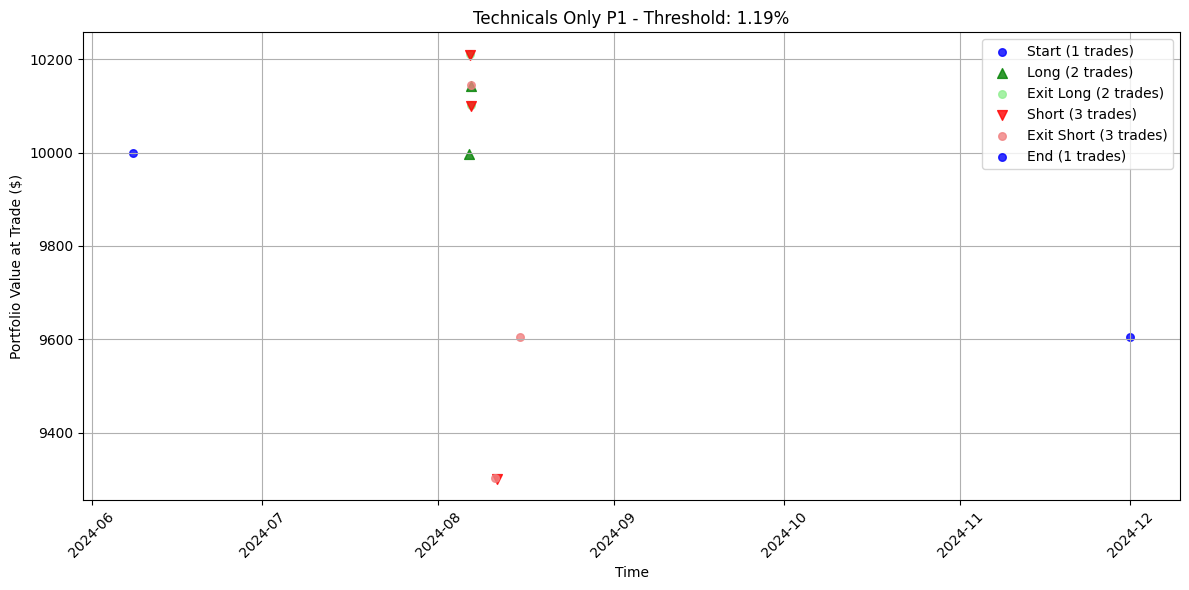


--- Test Period 2 ---
Backtest trades saved to backtest_results/technicals_only/threshold_backtest_trades-2.csv (22 trades)


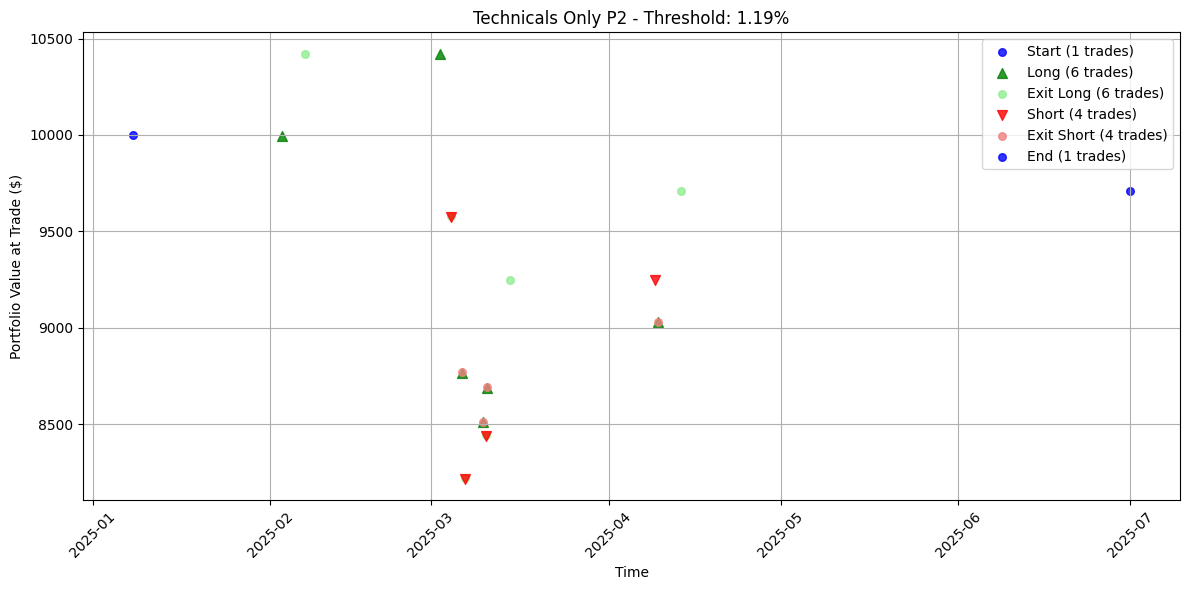

In [7]:
# CV Optimization and Backtesting on Test Data
initial_capital = 10000
fixed_transaction_cost_pct = 0.0275
seq_length = 24*7  # 7 days

print("Performing CV optimization on training data...")

# CV optimize threshold parameters
print("CV optimizing threshold parameters...")
# Load CPU model for CV
cv_model, cv_device = load_model(model_path, num_variates=10, lookback_len=24*7, dim=64, depth=2, heads=4, device='cpu')
best_threshold, best_hold_hours = cv_optimize_threshold_parameters(
    train_df, cv_model, cv_device, seq_length, 'price_change_1h', initial_capital, fixed_transaction_cost_pct, include_target=True
)

print(f"\nOptimized parameters:")
print(f"Threshold: {best_threshold:.2f}%")
print(f"Hold Hours: {best_hold_hours}")

# Now backtest on test periods with optimized parameters
print("\n" + "="*50)
print("BACKTESTING ON TEST DATA")
print("="*50)

# Test Period 1 Backtests
print("\n--- Test Period 1 ---")
X_test_p1, _ = create_sequences(val_df_period1, 'price_change_1h', seq_length, include_target=True)
X_test_p1_tensor = prepare_tensor(X_test_p1, device)
test_pred_p1 = make_predictions(model, X_test_p1_tensor, device, df_hourly.columns.get_loc('price_change_1h'))
close_price_p1 = val_df_period1['close'][seq_length:].values
plot_index_p1 = val_df_period1.index[len(val_df_period1) - len(close_price_p1):]

# Threshold backtest on period 1
portfolio_history_optimal, trade_times, trade_values, trade_types = backtest_profit_threshold_with_trades(
    close_price_p1, test_pred_p1, initial_capital, best_threshold, fixed_transaction_cost_pct, best_hold_hours
)
trades_df = create_trades_dataframe(trade_times, trade_values, trade_types, plot_index_p1, "Threshold Backtest P1")
save_trades_to_csv(trades_df, 'backtest_results/technicals_only/threshold_backtest_trades-1.csv')
plot_trades(trades_df, f'Technicals Only P1 - Threshold: {best_threshold:.2f}%')

print("\n--- Test Period 2 ---")
X_test_p2, _ = create_sequences(val_df_period2, 'price_change_1h', seq_length, include_target=True)
X_test_p2_tensor = prepare_tensor(X_test_p2, device)
test_pred_p2 = make_predictions(model, X_test_p2_tensor, device, df_hourly.columns.get_loc('price_change_1h'))
close_price_p2 = val_df_period2['close'][seq_length:].values
plot_index_p2 = val_df_period2.index[len(val_df_period2) - len(close_price_p2):]

# Threshold backtest on period 2
portfolio_history_optimal, trade_times, trade_values, trade_types = backtest_profit_threshold_with_trades(
    close_price_p2, test_pred_p2, initial_capital, best_threshold, fixed_transaction_cost_pct, best_hold_hours
)
trades_df = create_trades_dataframe(trade_times, trade_values, trade_types, plot_index_p2, "Threshold Backtest P2")
save_trades_to_csv(trades_df, 'backtest_results/technicals_only/threshold_backtest_trades-2.csv')
plot_trades(trades_df, f'Technicals Only P2 - Threshold: {best_threshold:.2f}%')

CV optimizing risk parameters...
Using 15 cores for parallel Optuna optimization (on cpu)
Processing CV fold 1/10 for risk optimization...


[I 2025-12-09 22:49:17,078] A new study created in memory with name: no-name-b4e6fddd-5528-4a54-9654-1947d9ecca6b
[I 2025-12-09 22:49:17,109] Trial 0 finished with value: -0.3578031697240616 and parameters: {'threshold': 1.1714849435421246, 'target_risk': 2.15009772869336, 'hold_hours': 90}. Best is trial 0 with value: -0.3578031697240616.
[I 2025-12-09 22:49:17,109] Trial 0 finished with value: -0.3578031697240616 and parameters: {'threshold': 1.1714849435421246, 'target_risk': 2.15009772869336, 'hold_hours': 90}. Best is trial 0 with value: -0.3578031697240616.
[I 2025-12-09 22:49:17,114] Trial 1 finished with value: 0.8546296385386792 and parameters: {'threshold': 0.18546933321510015, 'target_risk': 1.2211666658092122, 'hold_hours': 150}. Best is trial 1 with value: 0.8546296385386792.
[I 2025-12-09 22:49:17,114] Trial 1 finished with value: 0.8546296385386792 and parameters: {'threshold': 0.18546933321510015, 'target_risk': 1.2211666658092122, 'hold_hours': 150}. Best is trial 1 wi

Fold 1 - Best threshold: 0.54%, Risk: 0.64%, Hold hours: 158, Sharpe: 4.04
Processing CV fold 2/10 for risk optimization...


[I 2025-12-09 22:49:27,902] A new study created in memory with name: no-name-6d91cfef-735f-437f-bc4a-e50bdf0fbfa9
[I 2025-12-09 22:49:27,920] Trial 0 finished with value: -0.8317595303313347 and parameters: {'threshold': 0.33343033768106345, 'target_risk': 0.7007483800353292, 'hold_hours': 74}. Best is trial 0 with value: -0.8317595303313347.
[I 2025-12-09 22:49:27,920] Trial 0 finished with value: -0.8317595303313347 and parameters: {'threshold': 0.33343033768106345, 'target_risk': 0.7007483800353292, 'hold_hours': 74}. Best is trial 0 with value: -0.8317595303313347.
[I 2025-12-09 22:49:27,938] Trial 1 finished with value: 0.007736369359662865 and parameters: {'threshold': 0.4598934519174663, 'target_risk': 1.2194648120992189, 'hold_hours': 82}. Best is trial 1 with value: 0.007736369359662865.
[I 2025-12-09 22:49:27,938] Trial 1 finished with value: 0.007736369359662865 and parameters: {'threshold': 0.4598934519174663, 'target_risk': 1.2194648120992189, 'hold_hours': 82}. Best is tr

Fold 2 - Best threshold: 0.77%, Risk: 1.43%, Hold hours: 15, Sharpe: 2.18
Processing CV fold 3/10 for risk optimization...


[I 2025-12-09 22:49:38,037] A new study created in memory with name: no-name-956885e2-ad9b-4e59-81c2-b06ad4170f3d
[I 2025-12-09 22:49:38,066] Trial 0 finished with value: -1.2646063275231532 and parameters: {'threshold': 0.3089666197474532, 'target_risk': 2.085565660156539, 'hold_hours': 56}. Best is trial 0 with value: -1.2646063275231532.
[I 2025-12-09 22:49:38,066] Trial 0 finished with value: -1.2646063275231532 and parameters: {'threshold': 0.3089666197474532, 'target_risk': 2.085565660156539, 'hold_hours': 56}. Best is trial 0 with value: -1.2646063275231532.
[I 2025-12-09 22:49:38,079] Trial 1 finished with value: -1.2551084518354039 and parameters: {'threshold': 1.6822454191250593, 'target_risk': 0.46792224361668217, 'hold_hours': 161}. Best is trial 1 with value: -1.2551084518354039.
[I 2025-12-09 22:49:38,096] Trial 3 finished with value: -0.030244264858649235 and parameters: {'threshold': 1.9613051241458743, 'target_risk': 1.920171048136302, 'hold_hours': 4}. Best is trial 3

... (11 outputs left out)

[I 2025-12-09 22:50:38,814] A new study created in memory with name: no-name-2d9e5254-c734-40f2-b939-d6a5cdfc65c5
[I 2025-12-09 22:50:38,827] Trial 0 finished with value: 0.7928010626528016 and parameters: {'threshold': 1.0477924834820962, 'target_risk': 2.202571681869779, 'hold_hours': 66}. Best is trial 0 with value: 0.7928010626528016.
[I 2025-12-09 22:50:38,827] Trial 0 finished with value: 0.7928010626528016 and parameters: {'threshold': 1.0477924834820962, 'target_risk': 2.202571681869779, 'hold_hours': 66}. Best is trial 0 with value: 0.7928010626528016.
[I 2025-12-09 22:50:38,840] Trial 1 finished with value: 1.0909028624404458 and parameters: {'threshold': 1.2116607366425332, 'target_risk': 2.205094326427298, 'hold_hours': 72}. Best is trial 1 with value: 1.0909028624404458.
[I 2025-12-09 22:50:38,852] Trial 2 finished with value: 0.0 and parameters: {'threshold': 1.9427601984950726, 'target_risk': 1.542103479218656, 'hold_hours': 31}. Best is trial 1 with value: 1.09090286244

Fold 9 - Best threshold: 1.06%, Risk: 2.17%, Hold hours: 166, Sharpe: 3.92
Processing CV fold 10/10 for risk optimization...


[I 2025-12-09 22:50:48,355] A new study created in memory with name: no-name-de4f3b09-079b-48f6-9fa5-535fa0343e3f
[I 2025-12-09 22:50:48,378] Trial 0 finished with value: 0.9433049338408275 and parameters: {'threshold': 0.5798911650116138, 'target_risk': 0.07348076886670417, 'hold_hours': 42}. Best is trial 0 with value: 0.9433049338408275.
[I 2025-12-09 22:50:48,384] Trial 1 finished with value: -0.4218527791477283 and parameters: {'threshold': 1.135588081467793, 'target_risk': 0.7816364802341823, 'hold_hours': 123}. Best is trial 0 with value: 0.9433049338408275.
[I 2025-12-09 22:50:48,378] Trial 0 finished with value: 0.9433049338408275 and parameters: {'threshold': 0.5798911650116138, 'target_risk': 0.07348076886670417, 'hold_hours': 42}. Best is trial 0 with value: 0.9433049338408275.
[I 2025-12-09 22:50:48,384] Trial 1 finished with value: -0.4218527791477283 and parameters: {'threshold': 1.135588081467793, 'target_risk': 0.7816364802341823, 'hold_hours': 123}. Best is trial 0 wi

Fold 10 - Best threshold: 1.78%, Risk: 0.04%, Hold hours: 155, Sharpe: 3.42
CV Optimal threshold: 1.16%, Risk: 1.10%, Hold hours: 95, Average Sharpe: 2.87

Optimized parameters:
Threshold: 1.16%
Target Risk: 1.10%
Hold Hours: 95

--- Test Period 1 ---
Backtest trades saved to backtest_results/technicals_only/risk_based_backtest_trades-1.csv (14 trades)


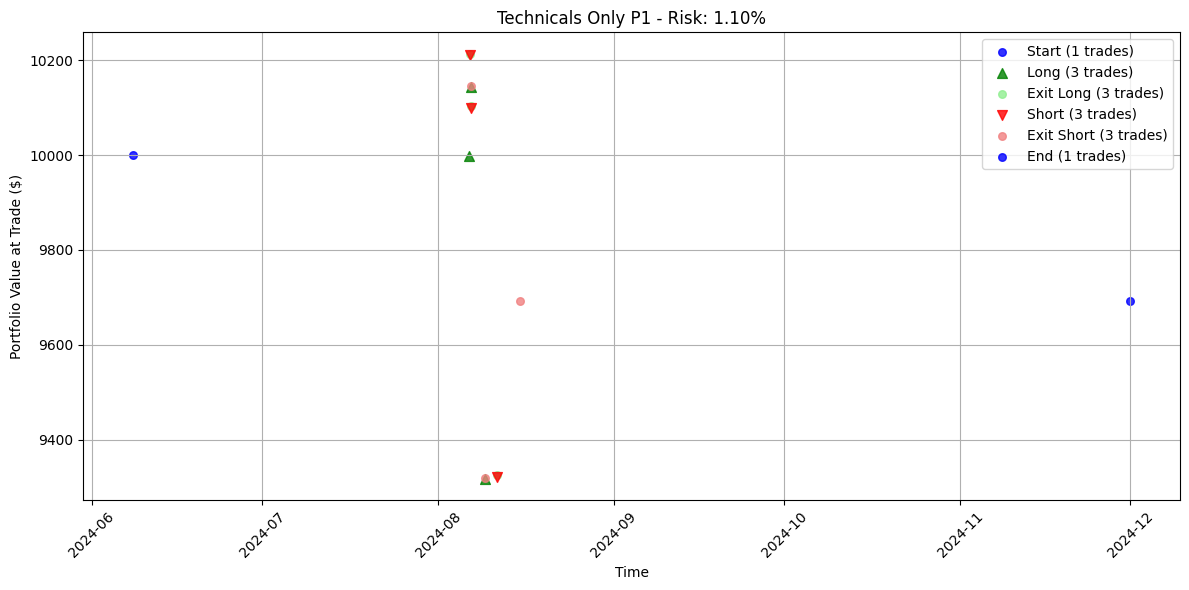


--- Test Period 2 ---
Backtest trades saved to backtest_results/technicals_only/risk_based_backtest_trades-2.csv (24 trades)


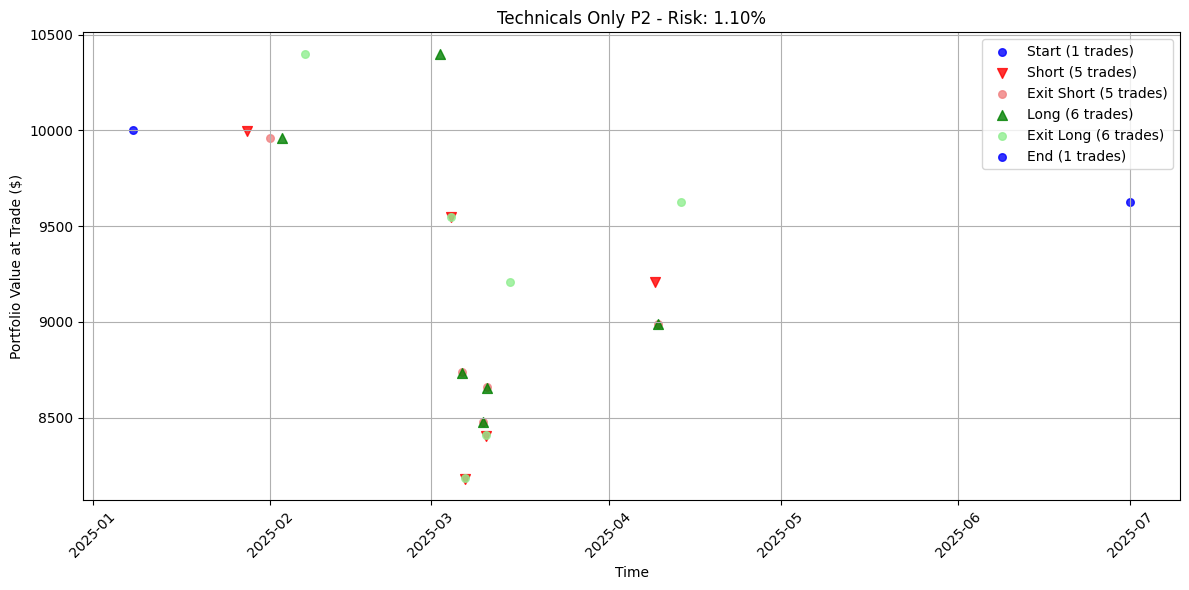

In [8]:
# CV optimize risk parameters
print("CV optimizing risk parameters...")
best_threshold, best_target_risk, best_hold_hours = cv_optimize_risk_parameters(
    train_df, cv_model, cv_device, seq_length, 'price_change_1h', initial_capital, fixed_transaction_cost_pct, include_target=True
)

print(f"\nOptimized parameters:")
print(f"Threshold: {best_threshold:.2f}%")
print(f"Target Risk: {best_target_risk:.2f}%")
print(f"Hold Hours: {best_hold_hours}")

print("\n--- Test Period 1 ---")
X_test_p1, _ = create_sequences(val_df_period1, 'price_change_1h', seq_length, include_target=True)
X_test_p1_tensor = prepare_tensor(X_test_p1, device)
test_pred_p1 = make_predictions(model, X_test_p1_tensor, device, df_hourly.columns.get_loc('price_change_1h'))
close_price_p1 = val_df_period1['close'][seq_length:].values
plot_index_p1 = val_df_period1.index[len(val_df_period1) - len(close_price_p1):]

# Risk-based backtest on period 1
portfolio_history_optimal, trade_times, trade_values, trade_types = backtest_profit_threshold(
    close_price_p1, test_pred_p1, initial_capital, best_threshold, target_risk_per_trade=best_target_risk, transaction_cost_pct=fixed_transaction_cost_pct, hold_hours=best_hold_hours
)
trades_df = create_trades_dataframe(trade_times, trade_values, trade_types, plot_index_p1, "Risk-Based Backtest P1")
save_trades_to_csv(trades_df, 'backtest_results/technicals_only/risk_based_backtest_trades-1.csv')
plot_trades(trades_df, f'Technicals Only P1 - Risk: {best_target_risk:.2f}%')

print("\n--- Test Period 2 ---")
X_test_p2, _ = create_sequences(val_df_period2, 'price_change_1h', seq_length, include_target=True)
X_test_p2_tensor = prepare_tensor(X_test_p2, device)
test_pred_p2 = make_predictions(model, X_test_p2_tensor, device, df_hourly.columns.get_loc('price_change_1h'))
close_price_p2 = val_df_period2['close'][seq_length:].values
plot_index_p2 = val_df_period2.index[len(val_df_period2) - len(close_price_p2):]

# Risk-based backtest on period 2
portfolio_history_optimal, trade_times, trade_values, trade_types = backtest_profit_threshold(
    close_price_p2, test_pred_p2, initial_capital, best_threshold, target_risk_per_trade=best_target_risk, transaction_cost_pct=fixed_transaction_cost_pct, hold_hours=best_hold_hours
)
trades_df = create_trades_dataframe(trade_times, trade_values, trade_types, plot_index_p2, "Risk-Based Backtest P2")
save_trades_to_csv(trades_df, 'backtest_results/technicals_only/risk_based_backtest_trades-2.csv')
plot_trades(trades_df, f'Technicals Only P2 - Risk: {best_target_risk:.2f}%')

CV optimizing momentum parameters...
Using 15 cores for parallel Optuna optimization (on cpu)
Processing CV fold 1/10 for momentum optimization...


[I 2025-12-09 22:50:58,783] A new study created in memory with name: no-name-a8afff9c-20e3-4db1-a199-105cc3624f12
[I 2025-12-09 22:50:58,801] Trial 0 finished with value: 1.2146460461549244 and parameters: {'lookback': 55, 'hold_hours': 81, 'signal_thresh': 0.8384522849405055, 'target_risk': 1.0725318515236486}. Best is trial 0 with value: 1.2146460461549244.
[I 2025-12-09 22:50:58,801] Trial 0 finished with value: 1.2146460461549244 and parameters: {'lookback': 55, 'hold_hours': 81, 'signal_thresh': 0.8384522849405055, 'target_risk': 1.0725318515236486}. Best is trial 0 with value: 1.2146460461549244.
[I 2025-12-09 22:50:58,840] Trial 1 finished with value: 0.3003380601379086 and parameters: {'lookback': 151, 'hold_hours': 136, 'signal_thresh': 0.2084242000819711, 'target_risk': 2.278314835123993}. Best is trial 0 with value: 1.2146460461549244.
[I 2025-12-09 22:50:58,850] Trial 2 finished with value: 0.7459474868643093 and parameters: {'lookback': 151, 'hold_hours': 164, 'signal_thre

Fold 1 - Best lookback: 92, hold_hours: 26, signal_thresh: 0.036, target_risk: 1.765, Sharpe: 3.71
Processing CV fold 2/10 for momentum optimization...


[I 2025-12-09 22:51:24,723] A new study created in memory with name: no-name-b4244011-284e-4b65-a6c8-2fe5ca78ffc6
[I 2025-12-09 22:51:24,758] Trial 0 finished with value: -0.3826940964720668 and parameters: {'lookback': 132, 'hold_hours': 137, 'signal_thresh': 0.7495436997357509, 'target_risk': 1.0035239422195865}. Best is trial 0 with value: -0.3826940964720668.
[I 2025-12-09 22:51:24,758] Trial 0 finished with value: -0.3826940964720668 and parameters: {'lookback': 132, 'hold_hours': 137, 'signal_thresh': 0.7495436997357509, 'target_risk': 1.0035239422195865}. Best is trial 0 with value: -0.3826940964720668.
[I 2025-12-09 22:51:24,761] Trial 2 finished with value: -0.4602917321579888 and parameters: {'lookback': 86, 'hold_hours': 15, 'signal_thresh': 1.1589424382936278, 'target_risk': 1.6406465650617943}. Best is trial 0 with value: -0.3826940964720668.
[I 2025-12-09 22:51:24,761] Trial 2 finished with value: -0.4602917321579888 and parameters: {'lookback': 86, 'hold_hours': 15, 'sig

Fold 2 - Best lookback: 10, hold_hours: 104, signal_thresh: 0.334, target_risk: 0.293, Sharpe: 3.42
Processing CV fold 3/10 for momentum optimization...


[I 2025-12-09 22:51:51,604] A new study created in memory with name: no-name-c86e3e09-9336-4ac7-999a-c835307768df
[I 2025-12-09 22:51:51,632] Trial 1 finished with value: 2.6893783535095794 and parameters: {'lookback': 145, 'hold_hours': 122, 'signal_thresh': 0.38046001568032195, 'target_risk': 2.0488521366740047}. Best is trial 1 with value: 2.6893783535095794.
[I 2025-12-09 22:51:51,632] Trial 1 finished with value: 2.6893783535095794 and parameters: {'lookback': 145, 'hold_hours': 122, 'signal_thresh': 0.38046001568032195, 'target_risk': 2.0488521366740047}. Best is trial 1 with value: 2.6893783535095794.
[I 2025-12-09 22:51:51,651] Trial 0 finished with value: 3.5334892941242813 and parameters: {'lookback': 158, 'hold_hours': 75, 'signal_thresh': 1.6237325354776637, 'target_risk': 0.36331585869345845}. Best is trial 0 with value: 3.5334892941242813.
[I 2025-12-09 22:51:51,651] Trial 0 finished with value: 3.5334892941242813 and parameters: {'lookback': 158, 'hold_hours': 75, 'signa

... (11 outputs left out)

[I 2025-12-09 22:54:25,701] A new study created in memory with name: no-name-ac70d7a0-8163-4d39-bbb6-ae2d2d9229e2
[I 2025-12-09 22:54:25,725] Trial 2 finished with value: -0.1056334375984415 and parameters: {'lookback': 73, 'hold_hours': 160, 'signal_thresh': 0.5204448504098037, 'target_risk': 0.597786461182393}. Best is trial 2 with value: -0.1056334375984415.
[I 2025-12-09 22:54:25,725] Trial 2 finished with value: -0.1056334375984415 and parameters: {'lookback': 73, 'hold_hours': 160, 'signal_thresh': 0.5204448504098037, 'target_risk': 0.597786461182393}. Best is trial 2 with value: -0.1056334375984415.
[I 2025-12-09 22:54:25,761] Trial 0 finished with value: -2.579537956687091 and parameters: {'lookback': 52, 'hold_hours': 18, 'signal_thresh': 1.284617762807477, 'target_risk': 1.5989810421902286}. Best is trial 2 with value: -0.1056334375984415.
[I 2025-12-09 22:54:25,761] Trial 0 finished with value: -2.579537956687091 and parameters: {'lookback': 52, 'hold_hours': 18, 'signal_thr

Fold 9 - Best lookback: 15, hold_hours: 145, signal_thresh: 0.756, target_risk: 0.114, Sharpe: 4.04
Processing CV fold 10/10 for momentum optimization...


[I 2025-12-09 22:54:52,182] A new study created in memory with name: no-name-691b9226-6710-41e2-a516-3d9cbcecf8cd
[I 2025-12-09 22:54:52,208] Trial 0 finished with value: -1.1159898079005088 and parameters: {'lookback': 53, 'hold_hours': 28, 'signal_thresh': 0.35678994784847023, 'target_risk': 1.7557286070837552}. Best is trial 0 with value: -1.1159898079005088.
[I 2025-12-09 22:54:52,208] Trial 0 finished with value: -1.1159898079005088 and parameters: {'lookback': 53, 'hold_hours': 28, 'signal_thresh': 0.35678994784847023, 'target_risk': 1.7557286070837552}. Best is trial 0 with value: -1.1159898079005088.
[I 2025-12-09 22:54:52,216] Trial 2 finished with value: -2.932429166274823 and parameters: {'lookback': 5, 'hold_hours': 66, 'signal_thresh': 0.13067748619869274, 'target_risk': 0.8820938312722668}. Best is trial 0 with value: -1.1159898079005088.
[I 2025-12-09 22:54:52,216] Trial 2 finished with value: -2.932429166274823 and parameters: {'lookback': 5, 'hold_hours': 66, 'signal_t

Fold 10 - Best lookback: 87, hold_hours: 81, signal_thresh: 1.991, target_risk: 0.255, Sharpe: 4.08
CV Optimal lookback: 54, hold_hours: 73, signal_thresh: 0.913, target_risk: 0.418, Average Sharpe: 3.42

Optimized parameters:
Lookback: 54
Hold Hours: 73
Signal Threshold: 0.913
Target Risk: 0.418

--- Test Period 1 ---
Backtest trades saved to backtest_results/technicals_only/momentum_backtest_trades-1.csv (209 trades)


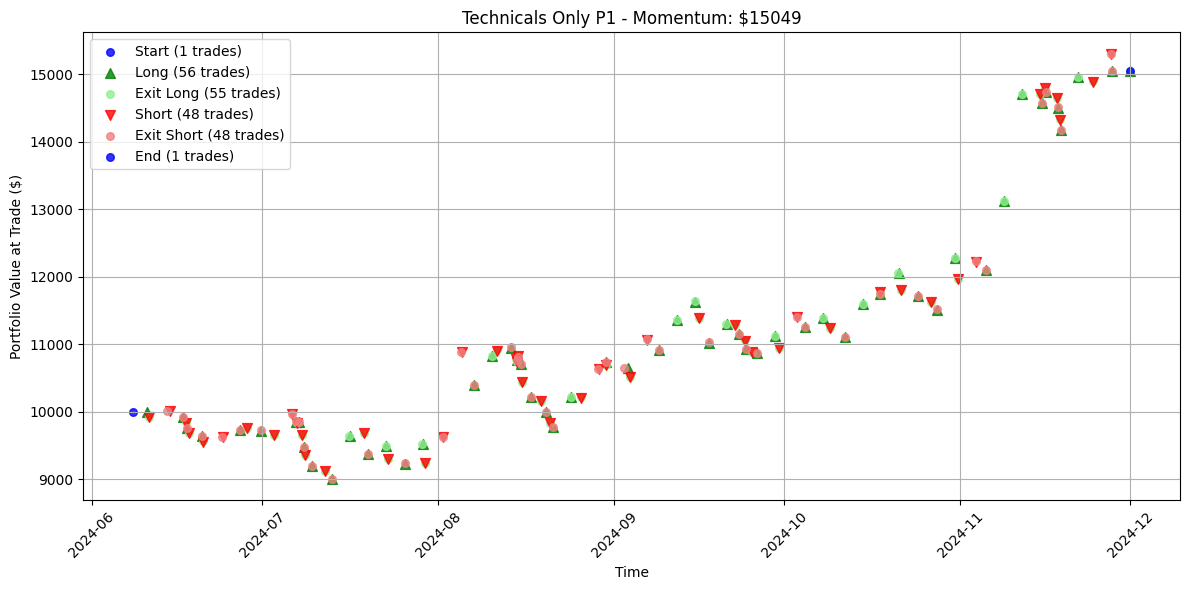


--- Test Period 2 ---
Backtest trades saved to backtest_results/technicals_only/momentum_backtest_trades-2.csv (239 trades)


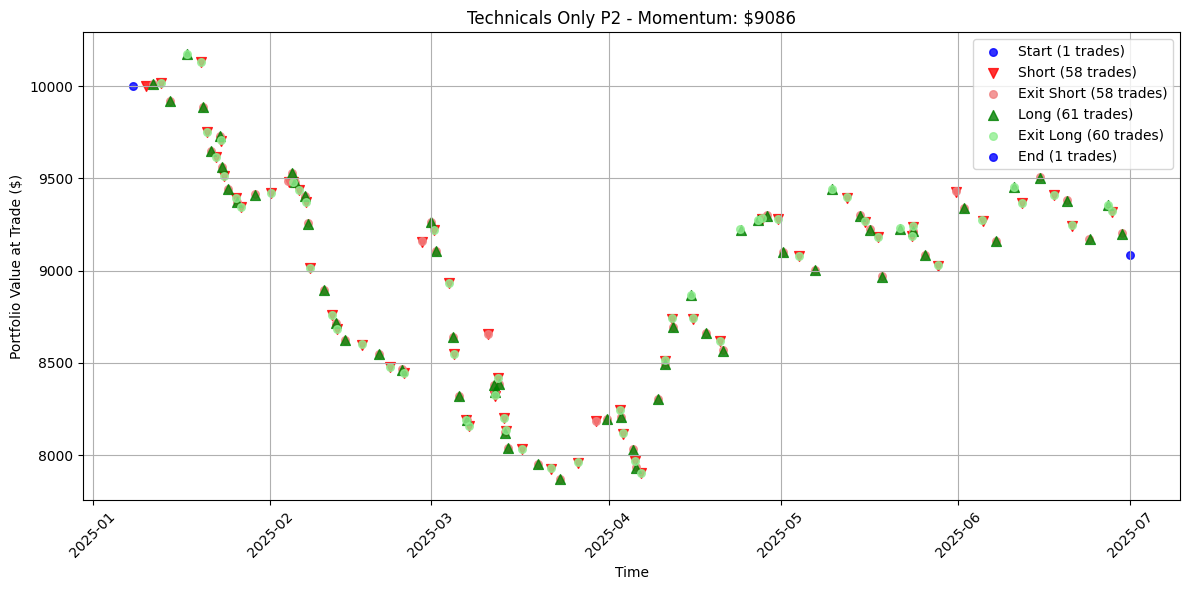

In [9]:
# CV optimize momentum parameters
print("CV optimizing momentum parameters...")
best_lookback, best_hold_hours, best_signal_thresh, best_target_risk = cv_optimize_momentum_parameters(
    train_df, cv_model, seq_length, 'price_change_1h', fixed_transaction_cost_pct, include_target=True
)

print(f"\nOptimized parameters:")
print(f"Lookback: {best_lookback}")
print(f"Hold Hours: {best_hold_hours}")
print(f"Signal Threshold: {best_signal_thresh:.3f}")
print(f"Target Risk: {best_target_risk:.3f}")

print("\n--- Test Period 1 ---")
X_test_p1, _ = create_sequences(val_df_period1, 'price_change_1h', seq_length, include_target=True)
X_test_p1_tensor = prepare_tensor(X_test_p1, device)
test_pred_p1 = make_predictions(model, X_test_p1_tensor, device, df_hourly.columns.get_loc('price_change_1h'))
close_price_p1 = val_df_period1['close'][seq_length:].values
plot_index_p1 = val_df_period1.index[len(val_df_period1) - len(close_price_p1):]

# Momentum backtest on period 1
final_capital_optimal, portfolio_history_optimal, trade_times_opt, trade_values_opt, trade_types_opt = backtest_ts_momentum(
    prices=close_price_p1,
    predicted_changes=test_pred_p1,
    lookback=best_lookback,
    hold_hours=best_hold_hours,
    target_risk_per_trade=best_target_risk,
    threshold=best_signal_thresh,
    initial_capital=10000,
    transaction_cost_pct=fixed_transaction_cost_pct)
trades_df = create_trades_dataframe(trade_times_opt, trade_values_opt, trade_types_opt, plot_index_p1, "Momentum Backtest P1")
save_trades_to_csv(trades_df, 'backtest_results/technicals_only/momentum_backtest_trades-1.csv')
plot_trades(trades_df, f'Technicals Only P1 - Momentum: ${final_capital_optimal:.0f}')

print("\n--- Test Period 2 ---")
X_test_p2, _ = create_sequences(val_df_period2, 'price_change_1h', seq_length, include_target=True)
X_test_p2_tensor = prepare_tensor(X_test_p2, device)
test_pred_p2 = make_predictions(model, X_test_p2_tensor, device, df_hourly.columns.get_loc('price_change_1h'))
close_price_p2 = val_df_period2['close'][seq_length:].values
plot_index_p2 = val_df_period2.index[len(val_df_period2) - len(close_price_p2):]

# Momentum backtest on period 2
final_capital_optimal, portfolio_history_optimal, trade_times_opt, trade_values_opt, trade_types_opt = backtest_ts_momentum(
    prices=close_price_p2,
    predicted_changes=test_pred_p2,
    lookback=best_lookback,
    hold_hours=best_hold_hours,
    target_risk_per_trade=best_target_risk,
    threshold=best_signal_thresh,
    initial_capital=10000,
    transaction_cost_pct=fixed_transaction_cost_pct)
trades_df = create_trades_dataframe(trade_times_opt, trade_values_opt, trade_types_opt, plot_index_p2, "Momentum Backtest P2")
save_trades_to_csv(trades_df, 'backtest_results/technicals_only/momentum_backtest_trades-2.csv')
plot_trades(trades_df, f'Technicals Only P2 - Momentum: ${final_capital_optimal:.0f}')